## 0. Setup Awal

In [1]:
import os
import time
import tracemalloc
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)

plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = 'outputNBAntiBurnoutMultinomial'
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

## 1. Data Understanding

### 1.1 Load Dataset

In [2]:
df = pd.read_csv('burnout_dataset1.csv')

print(f'Jumlah data awal: {len(df)}')

df = df.sample(
    n=5000,
    random_state=42
).reset_index(drop=True)
print(f'Jumlah data setelah sampling: {len(df)}')

Jumlah data awal: 50000
Jumlah data setelah sampling: 5000


### 1.2 Identifikasi Kolom yang Digunakan

In [3]:
numeric_columns = df.select_dtypes(
    include='number'
).columns

categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print('Kolom Numerik:')
print(
    numeric_columns.tolist()
)

print(
    '\nKolom Kategorikal:'
)
print(
    categorical_columns.tolist()
)

Kolom Numerik:
['Person_ID', 'Age', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score']

Kolom Kategorikal:
['Gender', 'Country', 'Occupation', 'Education_Level', 'Employment_Status', 'Remote_Work', 'Sleep_Quality', 'Stress_Level', 'Exercise_Frequency', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Mental_Health_Status', 'AI_Wellness_Recommendation', 'Burnout_Risk']


## 2. Preprocessing

### 2.1 Seleksi Kolom

In [4]:
y = df['Burnout_Risk'].copy()

numeric_columns = numeric_columns.drop(
    ['Person_ID', 'Burnout_Score'],
    errors='ignore'
)

categorical_columns = categorical_columns.drop(
    [
        'Gender',
        'Country',
        'Occupation',
        'AI_Wellness_Recommendation',
        'Burnout_Risk',
        'Education_Level',
        'Employment_Status'
    ],
    errors='ignore'
)

selected_columns = (
    list(numeric_columns)
    + list(categorical_columns)
)

X = df[
    selected_columns
].copy()

X.head()

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,19.0,NaN,58,8.0,9.0,9.6,56.0,35.0,54.0,37,...,Moderate,Never,Yes,No,No,No,No,No,Poor,Needs Attention
1,48.0,NaN,53,1.0,8.0,4.7,36.0,NaN,60.0,60,...,Moderate,Never,No,Yes,No,No,Yes,No,Excellent,Needs Attention
2,42.0,NaN,59,3.0,2.0,4.9,44.0,62.0,53.0,49,...,Moderate,Daily,No,Yes,No,No,No,No,Average,Needs Attention
3,22.0,NaN,49,9.0,8.0,6.3,72.0,65.0,29.0,35,...,High,Never,No,Yes,Yes,Yes,No,Yes,Average,Needs Attention
4,62.0,NaN,39,3.0,9.0,4.3,45.0,52.0,69.0,56,...,Moderate,Weekly,No,Yes,No,No,Yes,No,Poor,Needs Attention


### 2.2 Encoding Data Kategorikal

In [5]:
encoding_maps = {
    'Remote_Work': {
        'No': 0,
        'Hybrid': 1,
        'Yes': 2
    },

    'Sleep_Quality': {
        'Excellent': 0,
        'Good': 1,
        'Average': 2,
        'Poor': 3
    },

    'Stress_Level': {
        'Low': 0,
        'Moderate': 1,
        'High': 2
    },

    'Exercise_Frequency': {
        'Daily': 0,
        'Weekly': 1,
        'Rarely': 2,
        'Never': 3
    },

    'Alcohol_Consumption': {
        'No': 0,
        'Yes': 1
    },

    'Smoking': {
        'No': 0,
        'Yes': 1
    },

    'Healthy_Diet': {
        'No': 1,
        'Yes': 0
    },

    'Chronic_Stress': {
        'No': 0,
        'Yes': 1
    },

    'Family_History_Mental_Illness': {
        'No': 0,
        'Yes': 1
    },

    'Therapy_Attendance': {
        'No': 1,
        'Yes': 0
    },

    'Support_System': {
        'Poor': 3,
        'Average': 2,
        'Good': 1,
        'Excellent': 0
    },

    'Mental_Health_Status': {
        'Healthy': 0,
        'Needs Attention': 1,
        'Critical': 2
    }
}

for column, mapping in encoding_maps.items():

    X[column] = (
        X[column]
        .map(mapping)
    )

target_mapping = {
    'Low': 0,
    'Moderate': 1,
    'High': 2
}

y = y.map(target_mapping)

X[categorical_columns].head()

,Remote_Work,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,1,0,1,3,1,0,1,0,0,1.0,3,1
1,2,3,1,3,0,1,1,0,1,1.0,0,1
2,0,3,1,0,0,1,1,0,0,1.0,2,1
3,2,2,2,3,0,1,0,1,0,0.0,2,1
4,2,3,1,1,0,1,1,0,1,1.0,3,1


### 2.3 Penanganan Missing Values

In [6]:
print(
    'Missing value sebelum preprocessing:'
)

print(
    X.isnull().sum()
)

X = X.fillna(
    X.mean()
)

print(
    '\nJumlah missing value setelah preprocessing:'
)

print(
    X.isnull().sum()
)

Missing value sebelum preprocessing:
Age                                28
Monthly_Income_USD               1450
Work_Hours_Per_Week                 0
Job_Satisfaction                   37
Work_Life_Balance                  60
Sleep_Hours                        85
Anxiety_Score                      80
Depression_Score                   73
Mood_Score                         91
Emotional_Stability                 0
Physical_Activity_Hours           100
Meditation_Minutes                122
Screen_Time_Hours                  84
Social_Media_Hours                 62
Gaming_Hours                       69
Coffee_Cups_Per_Day                 0
Life_Satisfaction                  75
Productivity_Score                 80
Absenteeism_Days                    0
Remote_Work                         0
Sleep_Quality                       0
Stress_Level                        0
Exercise_Frequency                  0
Alcohol_Consumption                 0
Smoking                             0
Healthy_Diet 

### 2.4 Penanganan Outlier

### 2.5 Normalisasi (MinMaxScaler)

In [7]:
# Menggunakan MinMaxScaler karena MultinomialNB mensyaratkan nilai fitur non-negatif
scaler = MinMaxScaler()

X_scaled = scaler.fit_transform(
    X
)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_scaled

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,0.021277,0.502944,0.76,0.777778,0.888889,0.933333,0.56,0.350000,0.54,0.37,...,0.5,1.000000,1.0,0.0,1.0,0.0,0.0,1.000000,1.000000,0.5
1,0.638298,0.502944,0.66,0.000000,0.777778,0.116667,0.36,0.410367,0.60,0.60,...,0.5,1.000000,0.0,1.0,1.0,0.0,1.0,1.000000,0.000000,0.5
2,0.510638,0.502944,0.78,0.222222,0.111111,0.150000,0.44,0.620000,0.53,0.49,...,0.5,0.000000,0.0,1.0,1.0,0.0,0.0,1.000000,0.666667,0.5
3,0.085106,0.502944,0.58,0.888889,0.777778,0.383333,0.72,0.650000,0.29,0.35,...,1.0,1.000000,0.0,1.0,0.0,1.0,0.0,0.000000,0.666667,0.5
4,0.936170,0.502944,0.38,0.222222,0.888889,0.050000,0.45,0.520000,0.69,0.56,...,0.5,0.333333,0.0,1.0,1.0,0.0,1.0,1.000000,1.000000,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,0.702128,0.550704,1.00,0.000000,0.444444,0.316667,0.80,0.930000,0.19,0.24,...,1.0,0.333333,1.0,0.0,1.0,1.0,0.0,1.000000,0.333333,1.0
4996,0.638298,0.491999,0.32,0.222222,0.555556,0.316667,0.61,0.500000,0.52,0.34,...,0.5,0.000000,1.0,1.0,0.0,0.0,0.0,0.000000,1.000000,0.5
4997,0.255319,0.166203,0.84,0.666667,0.777778,0.066667,0.97,0.830000,0.03,0.02,...,1.0,0.333333,0.0,1.0,1.0,1.0,0.0,1.000000,0.666667,1.0
4998,0.638298,0.529831,0.96,0.555556,0.222222,0.116667,0.43,0.460000,0.58,0.61,...,0.5,0.000000,0.0,1.0,1.0,0.0,1.0,1.000000,0.000000,0.5


### 2.6 Data Bersih

In [8]:
print('Dimensi data fitur (X):', X.shape)
print('Dimensi data fitur ternormalisasi (X_scaled):', X_scaled.shape)
print('Dimensi data latih (X_train):', X_train.shape)
print('Dimensi data uji (X_test):', X_test.shape)
print('Jumlah missing value:', X_scaled.isnull().sum().sum())
print('\nDistribusi kelas target (y):')
print(y.value_counts())

X_scaled.head()

Dimensi data fitur (X): (5000, 31)
Dimensi data fitur ternormalisasi (X_scaled): (5000, 31)
Dimensi data latih (X_train): (4000, 31)
Dimensi data uji (X_test): (1000, 31)
Jumlah missing value: 0

Distribusi kelas target (y):
Burnout_Risk
0    2481
1    1512
2    1007
Name: count, dtype: int64


,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,0.021277,0.502944,0.76,0.777778,0.888889,0.933333,0.56,0.350000,0.54,0.37,...,0.5,1.000000,1.0,0.0,1.0,0.0,0.0,1.0,1.000000,0.5
1,0.638298,0.502944,0.66,0.000000,0.777778,0.116667,0.36,0.410367,0.60,0.60,...,0.5,1.000000,0.0,1.0,1.0,0.0,1.0,1.0,0.000000,0.5
2,0.510638,0.502944,0.78,0.222222,0.111111,0.150000,0.44,0.620000,0.53,0.49,...,0.5,0.000000,0.0,1.0,1.0,0.0,0.0,1.0,0.666667,0.5
3,0.085106,0.502944,0.58,0.888889,0.777778,0.383333,0.72,0.650000,0.29,0.35,...,1.0,1.000000,0.0,1.0,0.0,1.0,0.0,0.0,0.666667,0.5
4,0.936170,0.502944,0.38,0.222222,0.888889,0.050000,0.45,0.520000,0.69,0.56,...,0.5,0.333333,0.0,1.0,1.0,0.0,1.0,1.0,1.000000,0.5


## 3. Modeling

### 3.1 Inisialisasi Model Naive Bayes Multinomial

In [9]:
model = MultinomialNB(
    alpha=1.0
)

### 3.2 Eksekusi Model dan Pengukuran Komputasi

In [10]:
tracemalloc.start()
start_time = time.process_time()

model.fit(
    X_train,
    y_train
)

train_time = time.process_time() - start_time
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

train_memory_mb = peak / (1024 * 1024)

print(f'Waktu Eksekusi Training: {train_time:.4f} detik')
print(f'Penggunaan Memori Peak: {train_memory_mb:.4f} MB')

Waktu Eksekusi Training: 0.0312 detik
Penggunaan Memori Peak: 0.4216 MB


### 3.3 Prediksi Data Uji

In [11]:
y_pred = model.predict(
    X_test
)

df_prediksi = pd.DataFrame(
    {
        'Actual': y_test,
        'Predicted': y_pred
    },
    index=X_test.index
)

df_prediksi.head()

,Actual,Predicted
761,1,1
4863,0,0
3651,0,0
361,1,1
3197,0,0


## 4. Evaluasi

### 4.1 Laporan Klasifikasi (Classification Report)

In [12]:
target_names = ['Low (0)', 'Moderate (1)', 'High (2)']

report = classification_report(
    y_test,
    y_pred,
    target_names=target_names,
    digits=4
)

print(report)

              precision    recall  f1-score   support

     Low (0)     1.0000    0.9899    0.9949       496
Moderate (1)     0.7817    0.9571    0.8605       303
    High (2)     0.9058    0.6219    0.7375       201

    accuracy                         0.9060      1000
   macro avg     0.8958    0.8563    0.8643      1000
weighted avg     0.9149    0.9060    0.9025      1000



### 4.2 Matriks Kebingungan (Confusion Matrix)

In [13]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[491   5   0]
 [  0 290  13]
 [  0  76 125]]


### 4.3 Metrik Evaluasi Data Uji

In [14]:
acc = accuracy_score(
    y_test,
    y_pred
)

prec_macro = precision_score(
    y_test,
    y_pred,
    average='macro'
)

rec_macro = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1_macro = f1_score(
    y_test,
    y_pred,
    average='macro'
)

f1_weighted = f1_score(
    y_test,
    y_pred,
    average='weighted'
)

print(f'Accuracy           : {acc:.4f}')
print(f'Precision (Macro)  : {prec_macro:.4f}')
print(f'Recall (Macro)     : {rec_macro:.4f}')
print(f'F1-Score (Macro)   : {f1_macro:.4f}')
print(f'F1-Score (Weighted): {f1_weighted:.4f}')

Accuracy           : 0.9060
Precision (Macro)  : 0.8958
Recall (Macro)     : 0.8563
F1-Score (Macro)   : 0.8643
F1-Score (Weighted): 0.9025


### 4.4 Evaluasi Stratified 5-Fold Cross-Validation

In [15]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scoring = {
    'accuracy': 'accuracy',
    'precision_macro': 'precision_macro',
    'recall_macro': 'recall_macro',
    'f1_macro': 'f1_macro',
    'f1_weighted': 'f1_weighted'
}

cv_results = cross_validate(
    model,
    X_scaled,
    y,
    cv=cv,
    scoring=cv_scoring
)

df_cv = pd.DataFrame(
    {
        'Fold': [f'Fold {i+1}' for i in range(5)],
        'Accuracy': cv_results['test_accuracy'],
        'Precision (Macro)': cv_results['test_precision_macro'],
        'Recall (Macro)': cv_results['test_recall_macro'],
        'F1-Score (Macro)': cv_results['test_f1_macro'],
        'F1-Score (Weighted)': cv_results['test_f1_weighted']
    }
)

df_cv.loc['Mean'] = df_cv.mean(numeric_only=True)
df_cv.loc['Std'] = df_cv.std(numeric_only=True)
df_cv

,Fold,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted)
0,Fold 1,0.901000,0.890669,0.852514,0.859968,0.897944
1,Fold 2,0.894000,0.882086,0.839491,0.846724,0.889625
2,Fold 3,0.905000,0.898373,0.856092,0.864071,0.901505
3,Fold 4,0.914000,0.902688,0.867145,0.875229,0.910843
4,Fold 5,0.923000,0.914093,0.883344,0.891185,0.921087
Mean,NaN,0.907400,0.897582,0.859717,0.867435,0.904201
Std,NaN,0.010131,0.010837,0.014748,0.014972,0.010846


### 4.5 Ringkasan Waktu Eksekusi dan Penggunaan Memori

In [16]:
df_runtime = pd.DataFrame(
    [
        {
            'Model': 'Naive Bayes (MultinomialNB)',
            'Training_Time_Seconds': round(train_time, 4),
            'Peak_Memory_MB': round(train_memory_mb, 4)
        }
    ]
)

df_runtime

,Model,Training_Time_Seconds,Peak_Memory_MB
0,Naive Bayes (MultinomialNB),0.0312,0.4216


### 4.6 Ringkasan Evaluasi Model

In [17]:
evaluation_result = pd.DataFrame(
    {
        'Model': ['Naive Bayes (MultinomialNB)'],
        'Distribusi': ['Multinomial'],
        'Scaler': ['MinMaxScaler'],
        'Alpha': [1.0],
        'Accuracy': [round(acc, 4)],
        'Precision_Macro': [round(prec_macro, 4)],
        'Recall_Macro': [round(rec_macro, 4)],
        'F1_Score_Macro': [round(f1_macro, 4)],
        'F1_Score_Weighted': [round(f1_weighted, 4)],
        'CV_5Fold_Accuracy_Mean': [round(cv_results['test_accuracy'].mean(), 4)],
        'CV_5Fold_F1_Macro_Mean': [round(cv_results['test_f1_macro'].mean(), 4)],
        'Training_Time_s': [round(train_time, 4)],
        'Peak_Memory_MB': [round(train_memory_mb, 4)]
    }
)

evaluation_result

,Model,Distribusi,Scaler,Alpha,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB
0,Naive Bayes (MultinomialNB),Multinomial,MinMaxScaler,1.0,0.906,0.8958,0.8563,0.8643,0.9025,0.9074,0.8674,0.0312,0.4216


## 5. Visualisasi Hasil

### 5.1 Visualisasi Confusion Matrix Heatmap

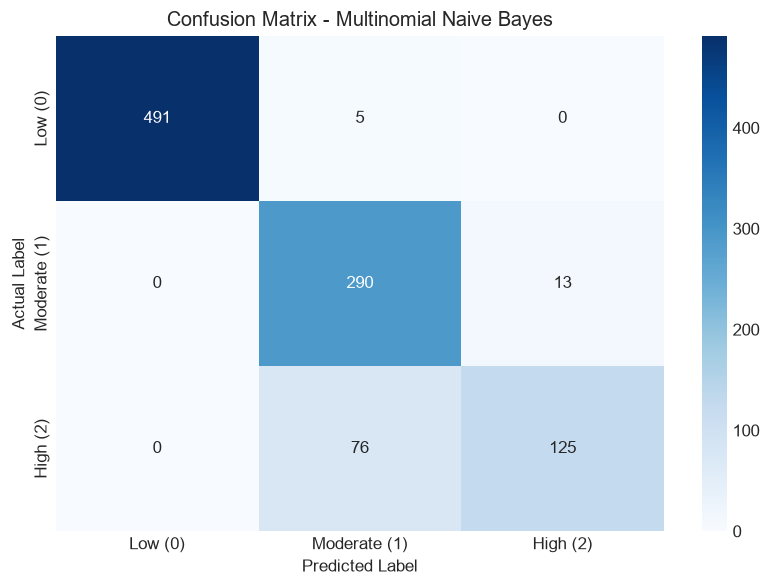

In [18]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names
)
plt.title('Confusion Matrix - Multinomial Naive Bayes')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/confusion_matrix_multinomial.png'
)
plt.show()

### 5.2 Visualisasi Distribusi Kelas Prediksi vs Aktual

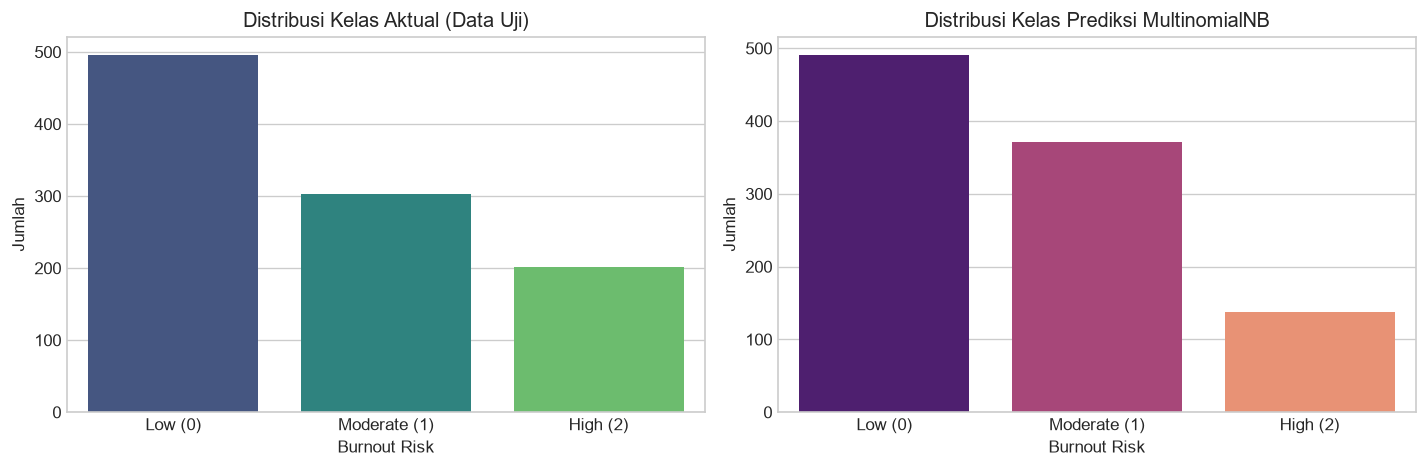

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    x=y_test,
    ax=axes[0],
    palette='viridis'
)
axes[0].set_title('Distribusi Kelas Aktual (Data Uji)')
axes[0].set_xticklabels(target_names)
axes[0].set_xlabel('Burnout Risk')
axes[0].set_ylabel('Jumlah')

sns.countplot(
    x=y_pred,
    ax=axes[1],
    palette='magma'
)
axes[1].set_title('Distribusi Kelas Prediksi MultinomialNB')
axes[1].set_xticklabels(target_names)
axes[1].set_xlabel('Burnout Risk')
axes[1].set_ylabel('Jumlah')

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/distribution_actual_vs_predicted_multinomial.png'
)
plt.show()

### 5.3 Visualisasi Metrik Evaluasi Stratified 5-Fold Cross-Validation

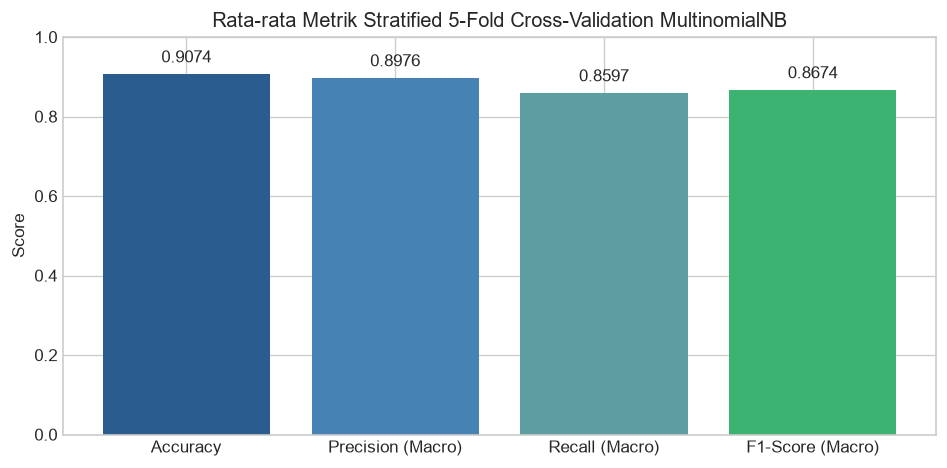

In [20]:
metrics_cv = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)']
cv_means = [
    cv_results['test_accuracy'].mean(),
    cv_results['test_precision_macro'].mean(),
    cv_results['test_recall_macro'].mean(),
    cv_results['test_f1_macro'].mean()
]

plt.figure(figsize=(8, 4))
bars = plt.bar(
    metrics_cv,
    cv_means,
    color=['#2b5c8f', '#4682b4', '#5f9ea0', '#3cb371']
)
plt.title('Rata-rata Metrik Stratified 5-Fold Cross-Validation MultinomialNB')
plt.ylabel('Score')
plt.ylim(0, 1)

for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.02,
        f'{yval:.4f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/cv_metrics_multinomial.png'
)
plt.show()

## 6. Analisis

### 6.1 Analisis Prior Probabilitas dan Log Probabilitas Fitur (Feature Log Prob)

In [21]:
df_priors = pd.DataFrame(
    {
        'Kelas': target_names,
        'Prior_Probability': [round(p, 4) for p in model.class_log_prior_]
    }
)

df_log_prob = pd.DataFrame(
    model.feature_log_prob_,
    columns=X.columns,
    index=target_names
)

print('Log Prior Probability per Kelas:')
display(df_priors)
print('\nFeature Log Probability per Kelas (10 Fitur Pertama):')
df_log_prob.T.head(10)

Log Prior Probability per Kelas:


,Kelas,Prior_Probability
0,Low (0),-0.7007
1,Moderate (1),-1.1965
2,High (2),-1.6020



Feature Log Probability per Kelas (10 Fitur Pertama):


,Low (0),Moderate (1),High (2)
Age,-3.322174,-3.429917,-3.488502
Monthly_Income_USD,-3.328934,-3.415509,-3.493033
Work_Hours_Per_Week,-3.719328,-3.253266,-3.083239
Job_Satisfaction,-3.321625,-3.395869,-3.462753
Work_Life_Balance,-3.337098,-3.372009,-3.530990
Sleep_Hours,-3.257353,-3.494813,-3.704404
Anxiety_Score,-4.203468,-3.401158,-3.090965
Depression_Score,-4.196274,-3.402909,-3.084647
Mood_Score,-2.893577,-3.411729,-4.186068
Emotional_Stability,-2.888820,-3.424946,-4.234314


### 6.2 Visualisasi 10 Fitur Paling Berpengaruh pada MultinomialNB

<Figure size 1440x720 with 0 Axes>

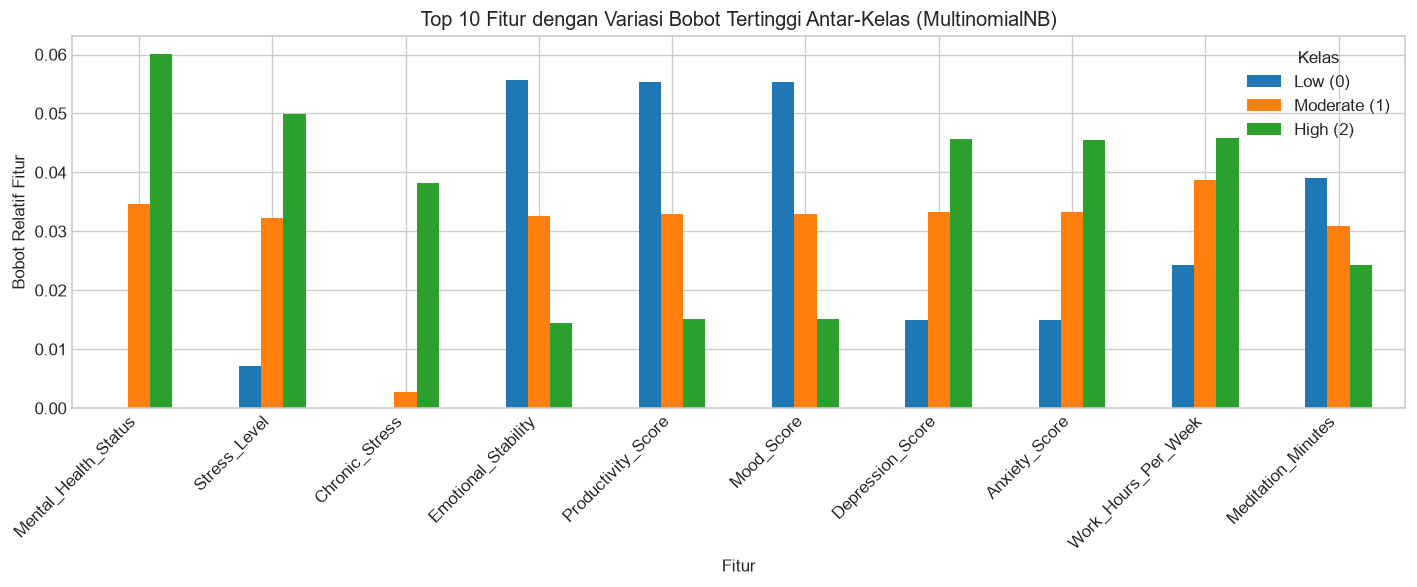

In [22]:
df_prob = pd.DataFrame(
    np.exp(model.feature_log_prob_),
    columns=X.columns,
    index=target_names
)

plt.figure(figsize=(12, 6))
top_diff = df_prob.std().sort_values(ascending=False).head(10)
df_prob[top_diff.index].T.plot(kind='bar', figsize=(12, 5))
plt.title('Top 10 Fitur dengan Variasi Bobot Tertinggi Antar-Kelas (MultinomialNB)')
plt.ylabel('Bobot Relatif Fitur')
plt.xlabel('Fitur')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Kelas')
plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/top_feature_probabilities_multinomial.png'
)
plt.show()

## 7. Ekspor File

### 7.1 Ekspor Ringkasan Evaluasi

In [23]:
evaluation_result.to_csv(
    f'{OUTPUT_DIR}/metrics_nb_multinomial.csv',
    index=False
)

### 7.2 Ekspor Hasil Prediksi Data Uji

In [24]:
df_prediksi.to_csv(
    f'{OUTPUT_DIR}/predictions_nb_multinomial.csv'
)

### 7.3 Ekspor Hasil 5-Fold Cross-Validation

In [25]:
df_cv.to_csv(
    f'{OUTPUT_DIR}/cv_5fold_nb_multinomial.csv'
)